### Lecture 7 : LinearRegression implementation

Instructor : **Muhammad Imtiaz**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file_path = '/content/drive/MyDrive/ML/L-2/sample_dataset_1000.csv'  # Ensure the correct file path
df = pd.read_csv(file_path)
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
# Display dataset information if loaded

print("\nDataset Preview:")
print(df.head())
print("\nColumn Names:")
print(df.columns)





Dataset Preview:
   ID    Name  Age  Gender    Salary Joining Date  Is Active  \
0   1    Paul   25  Female  90041.86   2017-01-31      False   
1   2    Paul   31    Male  90285.02   2019-05-29      False   
2   3  Rachel   30    Male  84321.65   2022-12-14      False   
3   4     Bob   45    Male  68189.99   2023-09-05       True   
4   5     Eve   34    Male  35428.35   2018-05-19       True   

            Comments  
0           Creative  
1  Needs Improvement  
2        Hardworking  
3       Fast Learner  
4          Dedicated  

Column Names:
Index(['ID', 'Name', 'Age', 'Gender', 'Salary', 'Joining Date', 'Is Active',
       'Comments'],
      dtype='object')


In [ ]:
# Rename columns for clarity
df.columns = ['ID', 'Name', 'Age', 'Gender', 'Salary', 'Joining Date', 'Is Active', 'Comments']
print("\nUpdated Column Names:")
print(df.columns)


Updated Column Names:
Index(['ID', 'Name', 'Age', 'Gender', 'Salary', 'Joining Date', 'Is Active',
       'Comments'],
      dtype='object')


In [ ]:
 # Select numeric columns for regression
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_cols.remove("ID")  # Remove ID as it's not useful for regression
print(numeric_cols)


['Age', 'Salary']


In [ ]:
# Define features (X) and target (Y)
X = df[['Age']]
Y = df['Salary']

In [ ]:
 # Split data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42)

In [ ]:
# Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, Y_train)

# Predict on test data
Y_pred = model.predict(X_test)

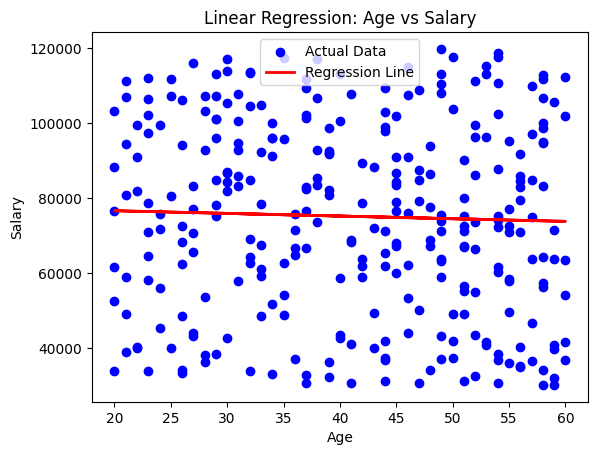

In [ ]:
# Plot regression line
plt.scatter(X_test, Y_test, color='blue', label='Actual Data')
plt.plot(X_test, Y_pred, color='red', linewidth=2, label='Regression Line')
plt.xlabel("Age")
plt.ylabel("Salary")
plt.title("Linear Regression: Age vs Salary")
plt.legend()
plt.show()

In [ ]:
# Display model coefficients
print("\nModel Coefficients:")
print(f"Intercept: {model.intercept_}")
print(f"Slope: {model.coef_[0]}")


Model Coefficients:
Intercept: 78099.31734165741
Slope: -70.86590271190651


In [ ]:
 # Predict for new data
new_ages = pd.DataFrame({'Age': [25, 30, 35, 40, 45]})
new_salaries = model.predict(new_ages)

print("\nPredicted Salaries for Given Ages:")
for age, salary in zip(new_ages['Age'], new_salaries):
    print(f"Age: {age}, Predicted Salary: {salary:.2f}")


Predicted Salaries for Given Ages:
Age: 25, Predicted Salary: 76327.67
Age: 30, Predicted Salary: 75973.34
Age: 35, Predicted Salary: 75619.01
Age: 40, Predicted Salary: 75264.68
Age: 45, Predicted Salary: 74910.35
